In [1]:
import jax
import jax.numpy as jnp
from functools import partial

## 2D Periodic - Ewald Coulomb sum

In [2]:
import jax
import jax.numpy as jnp
from jax.scipy.special import erf, erfc
jax.config.update("jax_enable_x64", True)

@partial(jax.jit, static_argnames=("n",))
def lattice_vecs(v1, v2, n):
    indices = jnp.arange(-n, n+1)
    n1, n2 = jnp.meshgrid(indices, indices, indexing='ij')
    vecs = n1[..., None] * v1 + n2[..., None] * v2
    return vecs.reshape(-1, 2)


def ewald_coulomb_2d(x, A1, A2, alpha, nreal=5, nrecip=10, cutoff=None):

    x = jnp.asarray(x).reshape(-1, 2)
    N = x.shape[0]

    cell = jnp.stack((A1, A2), axis=0)
    area = jnp.abs(jnp.linalg.det(cell))
    reciprocal = 2*jnp.pi*jnp.linalg.inv(cell).T
    B1, B2 = reciprocal[0], reciprocal[1]

    # ewald real sum
    R = lattice_vecs(A1, A2, n=nreal)   # (num_of_images, 2)
    displacement = x[:, None, None, :] - x[None, :, None, :] + R[None, None, :, :] # d_ijR = r_i - r_j + R

    # exclude only case: i==j and R==0
    same_particle = jnp.eye(N, dtype=bool)
    zero_image = jnp.all(R==0, axis=-1)
    excluded = same_particle[:, :, None] & zero_image[None, None, :] # i==j AND R==0
    r2 = jnp.sum(displacement**2, axis=-1)
    
    # replace excluded arguments before sqrt and division
    r = jnp.sqrt(jnp.where(excluded, 1.0, r2))
    real_terms = jnp.where(excluded, 0.0, erfc(alpha*r)/r)
    E_real = 0.5*jnp.sum(real_terms)

    # ewald reciprocal sum
    kvecs = lattice_vecs(B1, B2, n=nrecip)
    zero_mode = jnp.all(kvecs==0, axis=-1)
    k2 = jnp.sum(kvecs**2, axis=-1)
    k = jnp.sqrt(jnp.where(zero_mode, 1.0, k2))
    
    rho = jnp.sum(jnp.exp(1j*x @ kvecs.T), axis=0) # \sum_i exp(i k . r_i)
    kernel = jnp.where(zero_mode, 0.0, erfc(k/(2*alpha))/k)
    E_recip = (jnp.pi/area*jnp.sum(kernel*jnp.abs(rho)**2))

    # self and background corrections
    E_self = -N*alpha/jnp.sqrt(jnp.pi)
    E_background = -N**2 * jnp.sqrt(jnp.pi) / (area*alpha)

    return E_real + E_recip + E_self + E_background

## 3D periodic (HEG)
(From the MPNQS reference code)

In [3]:
import jax
import jax.numpy as jnp
import numpy as np

from functools import partial


@partial(jax.jit, static_argnums=(1,))
def smallest_vecs(basis, n):   
    # integer lattivce vectors, generating (nx, ny, nz) combination. or generating coordinates in integers
    dim = basis.shape[-1]
    r = np.arange(-n, (n + 1))  # produces O(n*n*n) numbers

    vecs = jnp.array(np.meshgrid(*(dim * (r,)))).T.reshape(-1, dim)
    return vecs


def ewald_coulomb(x, L, alpha, sdim=3, kmax=20, cutoff=None):
    """Ewald summation for cubic lattices."""

    if sdim != 3:
        raise ValueError("Ewald summation only implemented for 3 spatial dimensions.")

    if cutoff is None:
        cutoff = 2.0 * L

    N = x.shape[0] // sdim
    x = x.reshape(-1, N, sdim)

    dists = x[..., :, None, :] - x[..., None, :, :]
    V = L**sdim

    def real_sum(dists):
        """Real space part of Ewald summation"""

        # vec(R)=0
        mask = 1 - jnp.eye(N)
        d = jnp.linalg.norm(dists, axis=-1)    # (1, N, N)
        res1 = jnp.where(
            mask[jnp.newaxis, :], jax.scipy.special.erfc(alpha * d) / d, 0
        ).reshape(-1)   # elemetn wise if-else: calculate erfc for i !=j, and 0 if i=j   

        # vec(R)=L * vec(n)
        Rn = smallest_vecs(jnp.eye(sdim), 2) * L
        temp = jnp.linalg.norm(Rn, axis=-1)
        Rn = jnp.where(temp[:, None] <= cutoff, Rn, 0)  # exlude too far away neighbours
        temp = jnp.linalg.norm(Rn, axis=-1)
        d = jnp.linalg.norm(dists[..., None, :] + Rn, axis=-1)  # dij = | xi - xj + R |     # (1, N, N, number_of_images) 

        res2 = jnp.where(temp == 0, 0, jax.scipy.special.erfc(alpha * d) / d).reshape(
            -1
        )  # Rn=0 is special    # calculate nonzero image contribution. i = j is included, because the distance is not zero

        res = jnp.sum(res1) + jnp.sum(res2)
        return res

    def recip_sum(x):
        """Reciprocal space part of Ewald summation"""

        # vec(k)=1/L * vec(n)
        Gm = smallest_vecs(jnp.eye(sdim), kmax) / L
        # |vec(k)|>kmax
        G = jnp.linalg.norm(Gm, axis=-1, keepdims=True)
        Gm = jnp.where(G <= kmax / L, Gm, 0)
        G = jnp.linalg.norm(Gm, axis=-1)
        G2 = (G**2).reshape(-1)

        t1 = jnp.where(G2 == 0, 0, jnp.exp(-G2 * jnp.pi**2 / (alpha**2)) / G2)  
        # exp(-pi*+2 G**2 / alpha**2) / G*+2 = exp(-q**2 / (4 alpha**2))

        # structure factor
        S = jnp.sum(
            jnp.where(
                G2 == 0,
                0,
                jnp.exp(1j * 2 * jnp.pi * jnp.einsum("...ij,kj->...ik", x, Gm)), # einsum calculate: xi . Gk
            ),
            axis=-2,
        ).reshape(-1)
        # SG(R) = \sum_i exp(i 2pi G dot xi)

        t2 = jnp.abs(S) ** 2

        res = 1 / (V * jnp.pi) * jnp.sum(t1 * t2)
        return res

    def self_energy():
        return -N * alpha / jnp.sqrt(jnp.pi)

    def constant():
        V = L**sdim
        return -(N**2) * jnp.pi / (2 * alpha**2 * V)

    ereal = real_sum(dists)
    erec = recip_sum(x)
    eself = self_energy()
    const = constant()

    return 0.5 * ereal + 0.5 * erec + eself + const

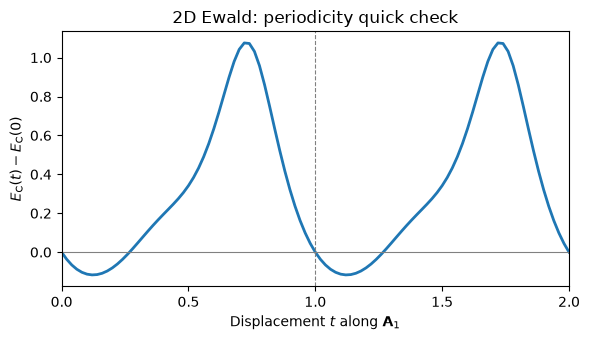

Maximum |E(t+1) - E(t)|: 1.78e-15


In [4]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

# test triangular simulation
aM = 1.0
a1 = aM * jnp.array([1.0, 0.0])
a2 = aM * jnp.array([0.5, jnp.sqrt(3.0) / 2])
M1, M2 = 3, 3
A1, A2 = M1 * a1, M2 * a2
cell = jnp.stack((A1, A2))  # Cell vectors are rows.

# just a fixed generic configuration, avoiding particle coincidences.
fractional = jnp.array([
    [0.13, 0.19],
    [0.41, 0.72],
    [0.78, 0.36],
    [0.67, 0.88],
])
x = fractional @ cell
alpha = 1.0

def energy(positions, nreal=8, nrecip=16):
    return float(ewald_coulomb_2d(
        positions, A1, A2,
        alpha=alpha,
        nreal=nreal,
        nrecip=nrecip,
    ))

E0 = energy(x)

# Move one electron through two simulation-cell periods. Keep all other electrons fixed, do not wrap coordinates.
t = np.linspace(0.0, 2.0, 101)
E = np.array([energy(x.at[0].add(s * A1)) for s in t])
delta_E = E - E[0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t, delta_E, color="tab:blue", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(1, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel(r"Displacement $t$ along $\mathbf{A}_1$")
ax.set_ylabel(r"$E_{\mathrm{C}}(t)-E_{\mathrm{C}}(0)$")
ax.set_title("2D Ewald: periodicity quick check")
ax.set_xticks([0, 0.5, 1, 1.5, 2])
ax.set_xlim(0,2)

plt.tight_layout()
plt.show()

# Compare corresponding points across the two periods.
period_error = np.max(np.abs(E[50:] - E[:51]))
print(f"Maximum |E(t+1) - E(t)|: {period_error:.2e}")

In [5]:
import jax.numpy as jnp

def moire_potential(r, a1, a2, V0):
    primitive_cell = jnp.stack([a1, a2], axis=0)
    reciprocal_cell = 2*jnp.pi*jnp.linalg.inv(primitive_cell).T
    b1, b2 = reciprocal_cell[0], reciprocal_cell[1]
    Gs = jnp.stack([b1, b2, b1+b2])

    V = 0
    for G in Gs:
        print("norm", G, ":", jnp.linalg.norm(G))
        V -= 2*V0*jnp.cos(jnp.dot(G, r))

    return V

a1 = jnp.array([1.0,0.0])
a2 = jnp.array([1/2,jnp.sqrt(3)/2])
V0 = 1
r = jnp.array([0,1])

print(moire_potential(r, a1, a2, V0))

norm [ 6.28318531 -3.62759873] : 7.255197456936871
norm [0.         7.25519746] : 7.255197456936872
norm [6.28318531 3.62759873] : 7.255197456936871
2.4095446551326214


## Moire potential

In [6]:
import jax.numpy as jnp

def moire_potential(r, a1, a2, V0):
    primitive_cell = jnp.stack((a1, a2))
    reciprocal = 2 * jnp.pi * jnp.linalg.inv(primitive_cell).T
    b1, b2 = reciprocal[0], reciprocal[1]

    # One member of each +/- pair in the shortest shell.
    G = jnp.stack((b1, b2, b1 + b2))

    phases = jnp.asarray(r) @ G.T
    return -2 * V0 * jnp.sum(jnp.cos(phases), axis=-1)


# def moire_energy(x, a1, a2, V0):
#     pass

## Helper

In [7]:
from flax import nnx
from typing import Any, Callable, Tuple, Sequence
import jax.numpy as jnp

import scipy

from netket.utils import HashableArray


class MLP(nnx.Module):
    def __init__(
        self,
        in_dim: int,
        out_dim: int,
        hidden_layers: tuple[int, ...],
        *,
        rngs: nnx.Rngs,
        activation: Callable = nnx.gelu,
        output_activation: Callable | None = None,
        last_bias: bool = True,
        last_linear: bool = True,
        auto_width: bool = False,
        dtype: Any = jnp.float32,
        kwargs: dict | None = None,
    ):
        self.activation = activation
        self.output_activation = output_activation
        self.last_linear = last_linear

        kwargs = kwargs or {}

        if auto_width and len(hidden_layers) == 1:
            n_hidden = hidden_layers[0]
            qs = [ k / ( n_hidden+1 ) for k in range(n_hidden + 2) ]
            dims = [ int( jnp.round(in_dim**(1-q) * out_dim**q )) for q in qs ]
        else:
            dims = [in_dim, *hidden_layers, out_dim]

        self.layers = nnx.List()
        for k in range(len(dims)-1):
            last = k == len(dims) - 2
            use_bias = (not last or last_bias or not last_linear)
            self.layers.append(
                nnx.Linear(
                    in_features=dims[k],
                    out_features=dims[k+1],
                    use_bias=use_bias,
                    param_dtype=dtype,
                    rngs=rngs,
                    **kwargs
                )
            )

    def __call__(self, x):
        for k, layer in enumerate(self.layers):
            last = k == len(self.layers) - 1

            x = layer(x)
            if last:
                if self.output_activation is not None:
                    x = self.output_activation(x)
                if not self.last_linear:
                    x = self.activation(x)
            else:
                x = self.activation(x)
        return x

class LogSlaterDet(nnx.Module):
    def __init__(
            self,
            n_per_spin: Tuple[int],
            orbitals: Sequence[Callable[..., Any]],
            return_signs: bool = False,
            add_signs: bool = True,
    ):
        self.n_per_spin = n_per_spin
        self.orbitals = nnx.data(orbitals)
        self.return_signs = return_signs
        self.add_signs = add_signs

    def __call__(self, r, dr, orbs=None, mask=True):
        if not self.orbitals:
            raise ValueError("Empty LogslaterDet module")

        assert(r.ndim == 3)
        N = r.shape[-2]

        mat = []
        for key, value in self.orbitals.items():
            o = value(r, dr)
            mat.append(o)
        mat = jnp.concatenate(mat, axis=-1)

        if mask:
            r = jnp.tile(
                jnp.array(self.n_per_spin[0]*[1] + self.n_per_spin[1]*[0])[:, None],
                (1, self.n_per_spin[0])
            )
            y = jnp.tile(
                jnp.array(self.n_per_spin[0]*[0] + self.n_per_spin[1]*[1])[:, None],
                (1, self.n_per_spin[1])
            )
            mask = jnp.concatenate((r, y), axis=-1)
            mat = mask[...,:,:] * jnp.exp(mat)

        if orbs is not None:
            mat = mat * jnp.exp(orbs)

        signs, logslaterdet = jnp.linalg.slogdet(mat)

        # normalization
        log_norm = 0.5 * jnp.log(scipy.special.factorial(N))
        logslaterdet -= log_norm

        if self.add_signs:
            logslaterdet = logslaterdet + jnp.log(signs)

        if self.return_signs:
            return signs, logslaterdet
        else:
            return logslaterdet


class Networks:
    def __init__(
        self,
        intermediate_dim: int, 
        num_intermediate: int, 
        embedding_dim: int,
        *,
        rngs: nnx.Rngs,
        activation: Callable = nnx.gelu
    ):
        """Create networks for the MPNQS
        Args:
            intermediate_dim: dimension of the intermediate coordinates
            num_intermediate: number of hidden layers
            embedding_dim: dimension of the final coordinates of the layer
        """
        self.intermediate_dim = intermediate_dim
        self.num_intermediate = num_intermediate
        self.embedding_dim = embedding_dim
        self.activation = activation
        self.rngs = rngs

    def Net(self, in_dim: int):
        return MLP(
            in_dim=in_dim,
            out_dim=self.embedding_dim,
            hidden_layers=self.num_intermediate * (self.intermediate_dim,),
            activation=self.activation,
            rngs=self.rngs
        )



class GraphUpdate(nnx.Module):
    def __init__(
            self,
            networks: Callable,
            L:float,
            n_up: int,
            n_down: int,
            attention_dim: int,
            edge_dim: int,
            *,
            rngs: nnx.Rngs
    ):
        self.L = L
        self.n_up = n_up
        self.n_down = n_down
        self.attention_dim = attention_dim
        embedding_dim = networks.embedding_dim

        self.phi = networks.Net(in_dim=edge_dim)
        self.f = networks.Net(in_dim=3*embedding_dim)
        self.f2 = networks.Net(in_dim=attention_dim)
        self.g = networks.Net(in_dim=edge_dim+embedding_dim)

        init = nnx.initializers.lecun_normal()
        self.wquery = nnx.Param(
            init(
                rngs.params(),
                (edge_dim, attention_dim),
                jnp.float64
            )
        )
        self.wkey = nnx.Param(
            init(
                rngs.params(),
                (edge_dim, attention_dim),
                jnp.float64
            )
        )

    def __call__(self, x, xij, x0, xij0, final):
        # xij: (..., N, N, d_edge)

        xquery = jnp.dot(xij, self.wquery[...])
        xkey = jnp.dot(xij, self.wkey[...])

        # (..., N, N, d_attention)
        attention_logits = jnp.einsum("...ijk,...jlk->...ilk", xquery, xkey) / jnp.sqrt(self.attention_dim)

        weight = self.f2(attention_logits)
        
        message = self.phi(xij) * weight  # ~ edge info x learned particle attention
        xnew = jnp.concatenate(
            (x0, self.f(jnp.concatenate((x, jnp.sum(message, axis=-2)), axis=-1))), axis=-1
        ) # x_i^(n+1) = [ x_i^(0), f(x_i^(n), m_i^(n) ]

        if not final:
            xij = jnp.concatenate(
                (xij0, self.g(jnp.concatenate((xij, message), axis=-1))), axis=-1
            ) # x_ij^(n+1) = [ x_ij^(0), g(x_ij^(n), m_ij^(n) ]
        return xnew, xij

class MPNN(nnx.Module):
    def __init__(
            self,
            n_up: int,
            n_down: int,
            embedding_dim: int,
            intermediate_dim: int,
            num_intermediate: int,
            attention_dim: int,
            *,
            rngs: nnx.Rngs,
            L: float = 1.0,
            n_interactions: int = 1
    ):
        self.n_up = n_up
        self.n_down = n_down
        self.embedding_dim = embedding_dim
        self.intermediate_dim = intermediate_dim
        self.num_intermediate_dim = num_intermediate
        self.attention_dim = attention_dim
        self.L = L
        self.n_interactions = n_interactions

        self.network_factory = Networks(intermediate_dim, num_intermediate, embedding_dim, rngs=rngs)
        self.X = nnx.Embed(
            num_embeddings=3,
            features=embedding_dim,
            dtype=np.float64,
            param_dtype=np.float64,
            embedding_init=lecun_normal(),
            rngs=rngs
        )
        edge_dim = 2 * sdim + 2 + embedding_dim
        self.layers = nnx.List([GraphUpdate(
                self.network_factory, self.L, self.n_up, self.n_down, self.attention_dim,
                edge_dim, rngs=rngs
            ) for _ in range(n_interactions)])

    def __call__(self, x):
        M, N, sdim = x.shape
        xembed = jnp.tile(self.X(jnp.array([0,1,2]))[None, ...], (M, 1, 1))

        # spin products (assuming first coordinates are spin up and then spin down)
        # s = jnp.hstack((self.n_up * [1], self.n_down * [-1]))
        # ss = jnp.outer(s, s)[..., None]
        s = jnp.concatenate((jnp.ones((self.n_up,)),
                            -jnp.ones((self.n_down,))))
        ss = jnp.outer(s, s)[..., None]

        # compute periodic distances and their norm
        dist = x[..., :, None, :] - x[..., None, :, :]
        d = jnp.linalg.norm(
            jnp.sin(jnp.pi / self.L * dist) + jnp.eye(N)[..., None],
            axis=-1,
            keepdims=True,
        ) * (1.0 - jnp.eye(N)[..., None])
        distp = jnp.concatenate(
            (jnp.sin(2 * jnp.pi / self.L * dist), jnp.cos(2 * jnp.pi / self.L * dist)),
            axis=-1,
        )

        # nodes (translation invariance requires no single particle coordinates)
        x0 = jnp.tile(xembed[:, 0, :][:, None, :], (1, N, 1))
        x = jnp.concatenate(
            (x0, jnp.tile(xembed[:, 1, :][:, None, :], (1, N, 1))), axis=-1
        )

        # edges
        xij0 = jnp.concatenate(
            (distp, d, jnp.tile(ss[None, :, :, :], (x.shape[0], 1, 1, 1))), axis=-1
        )
        xij = jnp.concatenate(
            (xij0, jnp.tile(xembed[:, 2, :][:, None, None, :], (1, N, N, 1))), axis=-1
        )

        for i, layer in enumerate(self.layers):
            final = i == self.n_interactions - 1
            x, xij = layer(x, xij, x0, xij0, final)

        return x

∣NK⟩ Tip: You can disable these tips by setting export NETKET_NO_TIPS=1 in your .bashrc.

## MPNQS

In [8]:
from flax import nnx
from netket.utils import HashableArray
from netket.utils.types import DType, NNInitFunc
from jax.nn.initializers import lecun_normal, ones, variance_scaling



class Bloch_Orbital(nnx.Module):
    def __init__(
            self,
            G,
            kvecs: HashableArray,
            n_orbs: int,
            *,
            rngs: nnx.Rngs,
            combine: bool = False,
            param_init = nnx.initializers.lecun_normal(),
            dtype = jnp.float32
    ):
        self.G = G              # (n_G, 2)
        self.kvecs = kvecs
        self.n_orbs = n_orbs

        # if combine:
        #     n_k = kvecs.shape[0]
        #     self.pw_coefficients = nnx.Param(param_init(rngs.params(), (n_k, n_orbs), dtype))
        n_k = kvecs.shape[0]

        self.u = MLP(
            in_dim = 2 * G.shape[0],
            out_dim = n_orbs,
            hidden_layers = (32, 32),
            rngs = rngs,
            dtype = dtype
        )

    def __call__(self, r, dr):
        log_plane_wave = 1j * jnp.einsum("ij,...j->...i", self.kvecs, r+dr)
        # if self.combine:
        #     plane_wave = jnp.einsum("ij,...i->...j", self.coefficients, res)
        angles = r @ self.G.T
        features = jnp.concatenate([jnp.sin(angles), jnp.cos(angles)], axis=-1)

        return self.u(features) + log_plane_wave


@partial(jax.jit, static_argnames=("m","n"))
def smallest_kvecs(v1, v2, m, n):
    indices = jnp.arange(-n, n+1)
    n1, n2 = jnp.meshgrid(indices, indices, indexing='ij')
    vecs = (n1[..., None] * v1 + n2[..., None] * v2).reshape(-1, 2)
    vecs = vecs[jnp.argsort(jnp.linalg.norm(vecs, axis=1))]
    return vecs[:m, :]


class MPNQS(nnx.Module):
    def __init__(
            self,
            n_per_spin: Tuple[int], # why
            sdim: int = 1,
            L: float = 1.0,
            paramsre_init = lecun_normal(),
            params_init = variance_scaling(0.0001, "fan_in", "truncated_normal"),
            scale_init = ones,
            dtype = jnp.float64,
            embedding_dim: int = 32,
            *,
            rngs: nnx.Rngs
    ):
        self.n_per_spin = n_per_spin
        self.sdim = sdim
        self.L = L
        self.dtype = dtype
        self.embedding_dim = embedding_dim

        # triangular architecture
        aM = 1.0
        a1 = aM * jnp.array([1.0, 0.0])
        a2 = aM * jnp.array([0.5, jnp.sqrt(3.0) / 2])
        cell = jnp.stack((a1, a2))  # Cell vectors are rows.
        G = 2*jnp.pi*jnp.linalg.inv(cell).T

        M1, M2 = 3, 3
        A1, A2 = M1 * a1, M2 * a2
        G1, G2 = 2*jnp.pi*jnp.linalg.inv(jnp.stack((A1, A2))).T
        self.k_vec = jnp.concatenate((
            smallest_kvecs(G1, G2, self.n_per_spin[0], 10),
            smallest_kvecs(G1, G2, self.n_per_spin[1], 10),
        ), axis=0)

        self.orb_basis = nnx.Dict(
            {
                "orbtials_up": Bloch_Orbital(G=G, kvecs=self.k_vec[: self.n_per_spin[0]], n_orbs=self.n_per_spin[0], combine=True, rngs=rngs, dtype=dtype),
                "orbtials_down": Bloch_Orbital(G=G, kvecs=self.k_vec[: self.n_per_spin[1]], n_orbs=self.n_per_spin[1], combine=True, rngs=rngs, dtype=dtype),
            }
        )

        self.MPNN = MPNN(
            *n_per_spin,
            embedding_dim=embedding_dim,
            intermediate_dim=32,
            num_intermediate=2,
            attention_dim=32,
            L=L,
            n_interactions=1,
            rngs=rngs
        )
        self.slater = LogSlaterDet(n_per_spin=n_per_spin, orbitals=self.orb_basis)
        self.net = MLP(in_dim=2 * embedding_dim + sdim, out_dim=1, hidden_layers=(32,), rngs=rngs)

        y_dim = 2 * embedding_dim

        self.prealup = nnx.Param(paramsre_init(
            rngs.params(), 
            (y_dim, sdim),
            dtype
        ))
        self.pimagup = nnx.Param(params_init(
            rngs.params(),
            (y_dim, self.sdim),
            dtype
        ))

    def __call__(self, r):
        shape = r.shape
        N = sum(self.n_per_spin)
        r = r.reshape(-1, N, self.sdim) # size: (batch, N, dim=2)
        M = r.shape[0]

        # BACKFLOW
        y = self.MPNN(r) # # size: (batch, N, 64) ; output of MPNN
        projection_weight_backflow = self.prealup + 1j * self.pimagup # 64,2
        dr = jnp.einsum("kd, ...ik->...id", projection_weight_backflow, y) # (batch, N, 2)

        r_plus_dr = r + dr

        k_vec = jnp.tile(self.k_vec[None, None, :, :], (M, N, 1, 1))
        jastrow = jnp.tile(y[:, :, None, :], (1, 1, N, 1))
        jastrow = jnp.concatenate((jastrow, k_vec), axis=-1)
        jastrow = self.net(jastrow).squeeze(axis=-1)
        psi = self.slater(r, dr, jastrow)

        return psi.reshape(shape[0])

## model, main

In [ ]:
import netket as nk

N = 14
# unpolarized
n_per_spin = (N // 2, N // 2)
sdim = 2
L = (4 * jnp.pi / 3 * N) ** (1 / 3)
rs = 2.0
nreal=8
nrecip=16

geometry = nk.experimental.geometry.Cell(d=2, L=L, pbc=True)
hilb = nk.experimental.hilbert.Particle(N=N, geometry=geometry)
sa = nk.sampler.MetropolisGaussian(hilb, sigma=0.04, n_chains=12, sweep_size=4)

ewald_coulomb_2d_potential = lambda x: ewald_coulomb_2d(x, A1, A2, alpha, nreal, nrecip)
H_coulomb_nk = 1/rs * nk.operator.PotentialEnergy(hilb, ewald_coulomb_2d_potential)

def moire_total_potential(x):
    positions = x.reshape(-1, 2)
    return jnp.sum(moire_potential(positions, a1, a2, V0))
H_moire_potential_nk = nk.operator.PotentialEnergy(hilb, moire_total_potential)

H_kinetic = nk.operator.KineticEnergy(hilb, mass=rs**2)

In [10]:
Hamiltonian = H_kinetic + H_moire_potential_nk + H_coulomb_nk

model = MPNQS(n_per_spin=n_per_spin, sdim=2, L=L, rngs=nnx.Rngs(0))

In [11]:
vs = nk.vqs.MCState(sa, model, n_samples=8, n_discard_per_chain=2)

op = nk.optimizer.Sgd(0.05)
sr = nk.optimizer.SR(diag_shift=0.0001)

log = nk.logging.JsonLog("HEG_14particles_test", save_params_every=7)

# gs = nk.VMC(ha, op, variational_state=vs, preconditioner=sr)
def mycb(step, logged_data, driver):
    logged_data["acceptance"] = float(driver.state.sampler_state.acceptance)
    return True
gs = nk.driver.VMC_SR(hamiltonian=Hamiltonian, optimizer=op, variational_state=vs, diag_shift=0.01)
gs.run(n_iter=2, callback=mycb, out=log)


/Users/azhar/venvs/nqs-continuum/lib/python3.12/site-packages/netket/vqs/mc/mc_state/state.py:316: UserWarning: n_samples=8 (8 per JAX device) does not divide n_chains=12, increased to 12 (12 per JAX device)
  self.n_samples = n_samples


Automatic SR implementation choice: NTK (n_parameters=23983, n_samples=12)
Automatic SR on_the_fly choice: True
online_statistics: chain_length=1, exponential moving average window: 50, decay=0.980


  0%|          | 0/2 [00:00<?, ?it/s]

(JsonLog('HEG_14particles_test', mode=write, autoflush_cost=0.005)
   Runtime cost:
   	Log:    0.0020198822021484375
   	Params: 0.002936840057373047,)